# 04 — Time-of-use schedules

**Concept:** a `Schedule` splits time into named **periods** (peak, off-peak, super-off-peak, …). Each period is defined by rules: daily time windows, optionally only on some days (weekends, or a Tempo-like colour) and in some seasons. Whatever no rule claims goes to a default. Every instant belongs to **exactly one** period, and `weights(grid)` gives the **share** of each step in each period.

**You will learn:** how to write a schedule in TOML or Python, why shares are fractions, how seasons, days and daylight-saving days behave, and how a contract gets two schedules (network and supplier) from its tariff pack.

## A supplier offer, written in TOML

This made-up offer for an electric car has a super-off-peak every night, extra off-peak hours on winter weekends, and a cheaper peak in summer. Off-peak hours are written as on a bill; any number of periods and seasons is allowed.

In [1]:
from datetime import date, datetime, timedelta
from decimal import Decimal
from pathlib import Path
from zoneinfo import ZoneInfo

import matplotlib.pyplot as plt

from myenergy.adapters.profiles.synthetic import SyntheticProfileSource
from myenergy.adapters.packs.toml_files import TomlPackSource, builtin_packs
from myenergy.adapters.tariffs.schedules import load_schedules, read_schedules
from myenergy.domain.errors import ScheduleError
from myenergy.domain.profiles import Nominal, ProfileRef, Shaped
from myenergy.domain.rates import RateKey
from myenergy.domain.schedules import WEEKDAYS, PeriodRule, Schedule, TimeWindows
from myenergy.domain.time import TimeGrid
from myenergy.engine.profiles import ProfileResolver

PARIS = ZoneInfo("Europe/Paris")
EV_FILE = Path("../tests/fixtures/schedules/ev-offer.toml")
print(EV_FILE.read_text())
ev = read_schedules(EV_FILE)["ev-offer"]
ev.periods

# A made-up supplier offer for an electric car: used by tests and notebook 04.
[schedules.ev-offer]
default = "peak"

[schedules.ev-offer.seasons]
winter = "11-01..03-31"
summer = { dates = "04-01..10-31", default = "summer-peak" }

[[schedules.ev-offer.periods]]
name = "super-off-peak"
windows = "02:00-06:00"

[[schedules.ev-offer.periods]]
name = "off-peak"
windows = "22:00-02:00 06:00-08:00"
days = ["sat", "sun"]
seasons = ["winter"]



('super-off-peak', 'off-peak', 'summer-peak', 'peak')

In [2]:
def day(month: int, dom: int, minutes: int = 60, days: int = 1) -> TimeGrid:
    start = datetime(2026, month, dom, tzinfo=PARIS)
    return TimeGrid(start=start, end=start + timedelta(days=days),
                    step=timedelta(minutes=minutes))


def show(schedule: Schedule, grid: TimeGrid, calendar=WEEKDAYS) -> None:
    weights = schedule.weights(grid, calendar)
    for i, row in enumerate(weights.shares):
        parts = " + ".join(f"{s:g} {p}" if s < 1 else p
                           for p, s in zip(weights.periods, row) if s > 0)
        print(f"{weights.grid.local(i):%a %d %b %H:%M}  {parts}")


show(ev, day(1, 10).sub(datetime(2026, 1, 10, tzinfo=PARIS),
                         datetime(2026, 1, 10, 10, tzinfo=PARIS)))  # a winter Saturday

Sat 10 Jan 00:00  off-peak
Sat 10 Jan 01:00  off-peak
Sat 10 Jan 02:00  super-off-peak
Sat 10 Jan 03:00  super-off-peak
Sat 10 Jan 04:00  super-off-peak
Sat 10 Jan 05:00  super-off-peak
Sat 10 Jan 06:00  off-peak
Sat 10 Jan 07:00  off-peak
Sat 10 Jan 08:00  peak
Sat 10 Jan 09:00  peak


Rules are read **per instant**: the window 22:00–02:00 limited to weekends covers Saturday 00:00–02:00 (from Friday's window) because those instants fall on a Saturday. The same morning on a summer Saturday has no weekend off-peak, and its peak is the summer peak:

In [3]:
show(ev, day(7, 11).sub(datetime(2026, 7, 11, tzinfo=PARIS),
                         datetime(2026, 7, 11, 10, tzinfo=PARIS)))

Sat 11 Jul 00:00  summer-peak
Sat 11 Jul 01:00  summer-peak
Sat 11 Jul 02:00  super-off-peak
Sat 11 Jul 03:00  super-off-peak
Sat 11 Jul 04:00  super-off-peak
Sat 11 Jul 05:00  super-off-peak
Sat 11 Jul 06:00  summer-peak
Sat 11 Jul 07:00  summer-peak
Sat 11 Jul 08:00  summer-peak
Sat 11 Jul 09:00  summer-peak


## Shares, not labels

With 60-minute steps and a window edge at 13:30, the step 13:00–14:00 is half in each period. Splitting by time keeps the energy per period exact on any grid.

In [4]:
hp_hc = Schedule(name="hp-hc", rules=(PeriodRule("HC", TimeWindows.parse("1H30-7H30 13H30-15H30")),),
                 default="HP")
show(hp_hc, day(1, 15).sub(datetime(2026, 1, 15, 12, tzinfo=PARIS),
                            datetime(2026, 1, 15, 16, tzinfo=PARIS)))

Thu 15 Jan 12:00  HP
Thu 15 Jan 13:00  0.5 HC + 0.5 HP
Thu 15 Jan 14:00  HC
Thu 15 Jan 15:00  0.5 HC + 0.5 HP


## Mistakes are named, never guessed

Two rules claiming the same instant, or an instant without any period, are errors that say where.

In [5]:
clash = load_schedules('''
[schedules.clash]
default = "day"
[[schedules.clash.periods]]
name = "night"
windows = "22:00-06:00"
[[schedules.clash.periods]]
name = "weekend"
days = ["weekend"]
''')["clash"]
try:
    clash.weights(day(1, 10))
except ScheduleError as error:
    print(error)
try:
    Schedule(name="gaps", rules=hp_hc.rules).weights(day(1, 15))
except ScheduleError as error:
    print(error)

schedule 'clash': rules night 22:00-06:00 and weekend days weekend both claim 2026-01-10 00:00 CET
schedule 'gaps' gives no period to 2026-01-15 00:00 CET; add a default


## Daylight-saving days

Shares are worked out in real (UTC) time: the window 01:30–07:30 loses an hour on the spring day and gains one on the autumn day.

In [6]:
for month, dom in ((1, 15), (3, 29), (10, 25)):
    weights = hp_hc.weights(day(month, dom, 15))
    print(f"2026-{month:02}-{dom:02}: {len(weights.grid) / 4:g} h in the day, "
          f"{weights.shares[:, 0].sum() / 4:g} h off-peak")

2026-01-15: 24 h in the day, 8 h off-peak
2026-03-29: 23 h in the day, 7 h off-peak
2026-10-25: 25 h in the day, 9 h off-peak


## Day calendars: the hook for Tempo-like offers

Day types come from a `DayCalendar`. The default gives weekday names, `weekday` and `weekend`; a colour calendar (to come, from a data source) adds labels such as `red`. Here a toy calendar makes every odd day red.

In [7]:
class ToyColours:
    vocabulary = WEEKDAYS.vocabulary | {"blue", "red"}

    def labels(self, d: date) -> frozenset[str]:
        return WEEKDAYS.labels(d) | {"red" if d.day % 2 else "blue"}


tempo_like = Schedule(
    name="tempo-like",
    rules=(PeriodRule("red-peak", TimeWindows.parse("06:00-22:00"), days=frozenset({"red"})),
           PeriodRule("off-peak", TimeWindows.parse("22:00-06:00"))),
    default="normal-peak",
)
weights = tempo_like.weights(day(1, 15, days=2), ToyColours())
{p: float(s) for p, s in zip(weights.periods, weights.shares.sum(axis=0))}  # hours over two days

{'red-peak': 16.0, 'off-peak': 16.0, 'normal-peak': 16.0}

## Network and supply schedules come from the contract's tariff pack

A contract follows a **tariff pack** (notebook 05). The built-in `fr-household` pack builds the network's four TURPE time classes (HPH, HCH, HPB, HCB) from the connection's off-peak hours, which may differ by season, and takes the **supplier's** schedule from the contract when given (any schedule), else from its supply option. TURPE gives households 8 off-peak hours a day; other values are accepted with a warning.

In [8]:
packs = TomlPackSource([builtin_packs()])
france = packs.pack("fr-household")
contract = france.contract(
    subscribed_kva=6,
    fields={"fta": "CU4", "supply_option": "hp-hc"},
    off_peak=TimeWindows.parse("1H30-7H30 13H30-15H30"),
    seasonal_off_peak={"low": TimeWindows.parse("02:00-06:00 11:00-15:00")},
    supply=ev,
)
print("network:", france.network_schedule(contract).periods)
print("supply: ", france.supply_schedule(contract).periods)
import warnings
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    france.contract(subscribed_kva=6, fields={"fta": "CU4", "supply_option": "base"},
                    off_peak=TimeWindows.parse("22:00-05:00"))
print(*(f"{w.category.__name__}: {w.message}" for w in caught), sep="\n")

network: ('HCH', 'HCB', 'HPH', 'HPB')
supply:  ('super-off-peak', 'off-peak', 'summer-peak', 'peak')


## A year of consumption, on both schedules

`split` gives kWh per period; the values always add up to the total. A synthetic household using 3,500 kWh a year, from 1 August 2025:

In [9]:
year = TimeGrid(start=datetime(2025, 8, 1, tzinfo=PARIS),
                end=datetime(2026, 8, 1, tzinfo=PARIS), step=timedelta(minutes=30))
resolver = ProfileResolver({"synthetic": SyntheticProfileSource(seed=1)})
load = resolver.power(Shaped(ref=ProfileRef(source="synthetic", key="household"),
                             scaling=Nominal(annual_kwh=3500)), year)
network = france.network_schedule(contract).weights(year).split(load)
supply = france.supply_schedule(contract).weights(year).split(load)
print(f"load over the year: {load.energy().total():.3f} kWh")
for name, split in (("network", network), ("supply", supply)):
    parts = ", ".join(f"{p} {v:.0f}" for p, v in split.items())
    print(f"{name:8} {parts}  (sum {sum(split.values()):.3f} kWh)")

load over the year: 3499.962 kWh
network  HCH 483, HCB 438, HPH 1234, HPB 1345  (sum 3499.962 kWh)
supply   super-off-peak 432, off-peak 120, summer-peak 1564, peak 1385  (sum 3499.962 kWh)


The network charge per kWh differs by class. With the CU4 rates from 1 August 2025 (from the pack's rate tables), a winter peak kWh pays about four and a half times the network rate of a summer peak kWh.

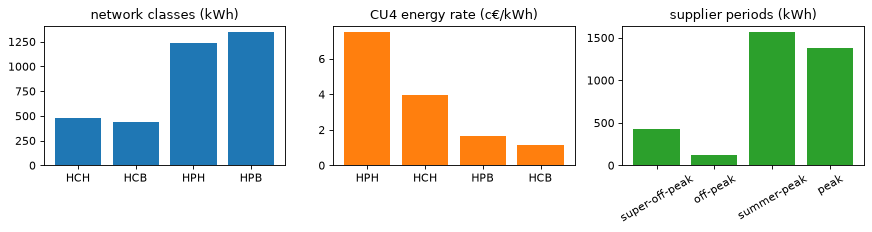

In [10]:
rates = packs.rates("fr-household")
classes = ("HPH", "HCH", "HPB", "HCB")
cost = {c: float(rates.history(RateKey.of("turpe.withdrawal.energy", segment=contract.field("segment"),
                                           fta=contract.field("fta"), time_class=c)
                  ).on(date(2025, 8, 1)).value) for c in classes}
fig, (left, mid, right) = plt.subplots(1, 3, figsize=(11, 3), dpi=80)
left.bar(list(network), list(network.values()))
left.set_title("network classes (kWh)")
mid.bar(classes, [100 * cost[c] for c in classes], color="tab:orange")
mid.set_title("CU4 energy rate (c€/kWh)")
right.bar(list(supply), list(supply.values()), color="tab:green")
right.set_title("supplier periods (kWh)")
right.tick_params(axis="x", labelrotation=30)
fig.tight_layout()

**Next:** [05 — Tariff packs](05-tariff-packs.ipynb): where contract fields, checks, network schedules and rates come from, and how to write your own.